
# Notebook 03 – Fraud Detection Baseline Models

## COS801 Deep Learning Project

**Project Title:** Deep Learning on Tabular Data for Fraud Detection under Extreme Class Imbalance

### Objective

This notebook will develops and evaluates the LightGBM baseline model using the IEEE-CIS Fraud Detection dataset.

The baseline will provide a reference for comparing traditional machine learning methods with deep learning architectures such as TabNet and FT-Transformer.

### Methodology

•	Using chronological training, and validation as well as testing datasets.
•	Recycle the preprocessing pipeline developed in Notebook 02.
•	Training in the tune of the lightGBM fraud detection model
•	The evaluation of the performance by using the precision I recall metrics and the fraud detection method
•	Maintains the results for the evaluation with the deep learning models


## 3.1 Installing the Required Libraries

In [1]:
# Section 3.1: Install required libraries

%pip install -q lightgbm kagglehub scikit-learn matplotlib seaborn


## 3.2 Importing the Required Libraries

In [2]:
# Section 3.2: Importing the required libraries

import os
import sys
import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
import kagglehub
import sklearn

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

print("All required libraries imported successfully!")
print("LightGBM version:", lgb.__version__)
print("Scikit-learn version:", sklearn.__version__)


All required libraries imported successfully!
LightGBM version: 4.6.0
Scikit-learn version: 1.6.1


## 3.3 Loading the Preprocessed Dataset

In [3]:
# Section 3.3: Upload reusable preprocessing script

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving preprocessing.py to preprocessing.py
Uploaded files: ['preprocessing.py']


In [4]:
# Section 3.3.3: Import and run the preprocessing pipeline

import os
import gc
import importlib

# Confirm that the preprocessing.py is available
assert os.path.isfile("preprocessing.py"), (
    "preprocessing.py was not found. Upload it first."
)

# Import our reusable preprocessing script
import preprocessing

# Reload the module if it was previously imported
importlib.reload(preprocessing)

# Run the complete preprocessing pipeline
model_data = preprocessing.run_preprocessing_pipeline()

# Extract training, validation and testing data
X_train = model_data["X_train"]
X_val = model_data["X_val"]
X_test = model_data["X_test"]

y_train = model_data["y_train"]
y_val = model_data["y_val"]
y_test = model_data["y_test"]

# Preserve transaction times for later evaluation
time_train = model_data["time_train"]
time_val = model_data["time_val"]
time_test = model_data["time_test"]

print("\nDATA READY FOR BASELINE MODELLING")
print("-" * 45)
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTraining fraud rate:", round(y_train.mean() * 100, 2), "%")
print("Validation fraud rate:", round(y_val.mean() * 100, 2), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 2), "%")


100%|██████████| 118M/118M [00:00<00:00, 184MB/s]

Extracting files...


Dataset loaded successfully!
Dataset shape: (590540, 394)

TEMPORAL DATA SPLITTING
---------------------------------------------
Training set: (413378, 394)
Validation set: (88581, 394)
Testing set: (88581, 394)

Chronological order verified!

PREPROCESSING COMPLETED
---------------------------------------------
Removed features: ['dist2', 'D7']
Numerical features: 375
Categorical features: 14

MODEL DATA PREPARED
---------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Testing features: (88581, 389)

DATA READY FOR BASELINE MODELLING
---------------------------------------------
X_train: (413378, 389)
X_val: (88581, 389)
X_test: (88581, 389)

Training fraud rate: 3.52 %
Validation fraud rate: 3.43 %
Testing fraud rate: 3.48 %


## 3.4 The training LightGBM based model

In this session, a LightGPM classifier using the chronologically separated training detail and the validation data set is used to monitor the performance of the model and to determine when the training should stop.

And the test data said it is reserved for the final evaluation to avoid the leakage.

In [5]:
# Section 3.4: Train the initial LightGBM baseline model

import time
import lightgbm as lgb

# Set a random seed for reproducibility
RANDOM_STATE = 42

# Define the baseline model
baseline_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

# Record training start time
start_time = time.time()

# Train using the training dataset
baseline_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=True
        ),
        lgb.log_evaluation(period=100)
    ]
)

# Calculate training time
training_time = time.time() - start_time

print("\nLIGHTGBM BASELINE TRAINING COMPLETED")
print("-" * 45)
print("Best iteration:", baseline_model.best_iteration_)
print("Training time (seconds):", round(training_time, 2))


Training until validation scores don't improve for 50 rounds
[100]	valid_0's average_precision: 0.533781	valid_0's binary_logloss: 0.0917812
[200]	valid_0's average_precision: 0.560846	valid_0's binary_logloss: 0.087724
[300]	valid_0's average_precision: 0.574886	valid_0's binary_logloss: 0.085776
[400]	valid_0's average_precision: 0.586061	valid_0's binary_logloss: 0.0843539
[500]	valid_0's average_precision: 0.591278	valid_0's binary_logloss: 0.0837194
[600]	valid_0's average_precision: 0.59742	valid_0's binary_logloss: 0.08292
[700]	valid_0's average_precision: 0.602127	valid_0's binary_logloss: 0.0823589
[800]	valid_0's average_precision: 0.605775	valid_0's binary_logloss: 0.0818775
Early stopping, best iteration is:
[829]	valid_0's average_precision: 0.607747	valid_0's binary_logloss: 0.0816243

LIGHTGBM BASELINE TRAINING COMPLETED
---------------------------------------------
Best iteration: 829
Training time (seconds): 88.34


## 3.5 Evaluation of the initial LightGBM baseline

in this session oil involved with the initially light GPM model using the money vision data set. And the evaluation it will focus on the average precision (PR – AUC), ROC -AUC, precision and recall as well as F1-score


In [6]:
# Section 3.5: Evaluate the initial LightGBM baseline

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Predict fraud probabilities using validation data
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

# Initial classification threshold
threshold = 0.50

# Convert probabilities into predicted classes
y_val_pred = (y_val_prob >= threshold).astype(int)

# Calculate evaluation metrics
pr_auc = average_precision_score(y_val, y_val_prob)
roc_auc = roc_auc_score(y_val, y_val_prob)
precision = precision_score(y_val, y_val_pred, zero_division=0)
recall = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)
brier = brier_score_loss(y_val, y_val_prob)

# Display evaluation results
print("INITIAL LIGHTGBM BASELINE EVALUATION")
print("-" * 45)

print("Validation PR-AUC:", round(pr_auc, 4))
print("Validation ROC-AUC:", round(roc_auc, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("Brier score:", round(brier, 4))

print("\nCONFUSION MATRIX")
print("-" * 45)
print(confusion_matrix(y_val, y_val_pred))


INITIAL LIGHTGBM BASELINE EVALUATION
---------------------------------------------
Validation PR-AUC: 0.6077
Validation ROC-AUC: 0.9276
Precision: 0.8665
Recall: 0.3669
F1-score: 0.5155
Brier score: 0.0201

CONFUSION MATRIX
---------------------------------------------
[[85367   172]
 [ 1926  1116]]


## 3.6 The precision recall Curve

The precision record curve evaluates the trade of in between the identifying fraud claims transaction entity meeting falls throughout alerts.
The average precision (AP) summarizes the performance of the model across the difference recall levels. And the evaluation is particularly important for the imbalance fraud direction data set.


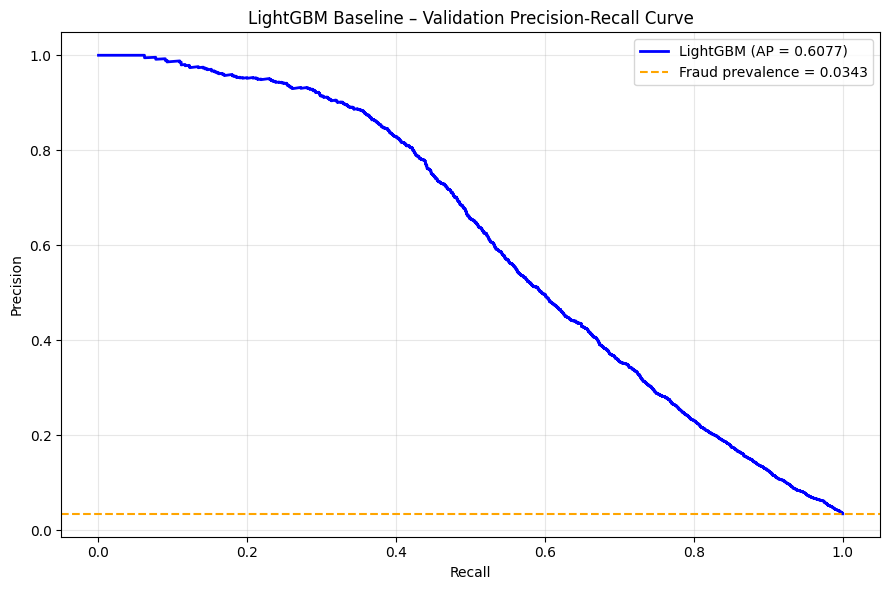

In [7]:
# Section 3.6: Plot precision-recall curve

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall across thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

# Calculate Average Precision
ap_score = average_precision_score(y_val, y_val_prob)

# Random ranking reference
fraud_rate = y_val.mean()

plt.figure(figsize=(9, 6))

plt.plot(
    recall_values,
    precision_values,
    color="blue",
    linewidth=2,
    label=f"LightGBM (AP = {ap_score:.4f})"
)

plt.axhline(
    y=fraud_rate,
    color="orange",
    linestyle="--",
    label=f"Fraud prevalence = {fraud_rate:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("LightGBM Baseline – Validation Precision-Recall Curve")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3.7 Precision at the fixed alert budget
This session evaluating the lightGBM baseline model which is under the limited fraud investigation capacity. The transactions are ranked based on their prediction of the fraud probabilities, as well as also the highest risk transition is selected for the investigation

The precision at the fixed alert budget measured the proportion of the selected transactions that are fraudulent. And the evaluation is the performance on the validation of dataset.


In [8]:
# Section 3.7: Precision at a fixed alert budget

import numpy as np
import pandas as pd

# Different investigation capacities:
# 0.5%, 1%, 2%, and 5% of validation transactions
alert_budgets = [0.005, 0.01, 0.02, 0.05]

# Prepare validation predictions
results_df = pd.DataFrame({
    "Actual_Fraud": np.asarray(y_val),
    "Fraud_Probability": y_val_prob
})

# Rank transactions from highest to lowest fraud risk
results_df = results_df.sort_values(
    by="Fraud_Probability",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

total_fraud = results_df["Actual_Fraud"].sum()
budget_results = []

for budget in alert_budgets:

    # Calculate number of transactions to investigate
    number_of_alerts = max(
        1,
        int(np.ceil(len(results_df) * budget))
    )

    # Select highest-risk transactions
    selected_alerts = results_df.head(number_of_alerts)

    # Count correctly detected fraud cases
    detected_fraud = int(
        selected_alerts["Actual_Fraud"].sum()
    )

    # Calculate precision and recall
    precision_at_budget = detected_fraud / number_of_alerts
    recall_at_budget = detected_fraud / total_fraud

    budget_results.append({
        "Alert Budget (%)": budget * 100,
        "Number of Alerts": number_of_alerts,
        "Fraud Detected": detected_fraud,
        "Precision": round(precision_at_budget, 4),
        "Recall": round(recall_at_budget, 4)
    })

# Display results
budget_results_df = pd.DataFrame(budget_results)

print("LIGHTGBM - PRECISION AT FIXED ALERT BUDGET")
print("-" * 55)

display(budget_results_df)


LIGHTGBM - PRECISION AT FIXED ALERT BUDGET
-------------------------------------------------------


,Alert Budget (%),Number of Alerts,Fraud Detected,Precision,Recall
0,0.5,443,431,0.9729,0.1417
1,1.0,886,826,0.9323,0.2715
2,2.0,1772,1348,0.7607,0.4431
3,5.0,4430,1951,0.4404,0.6414


### 3.8 The Expected Monetary Cost
This section evaluates the financial consequences of fraud detections by using an illustrative cost matrix. The false negative represents the fraudulent transactions which are missed, whereas the false positive represent the legitimate which are incorrectly flagged as fraud.

The assumption cost is explicitly stated to support the duplicability, and these values are hypothetical and do not represent the verified bank cost.


In [9]:
# Section 3.8: Expected monetary cost of the LightGBM baseline

from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

# Illustrative costs in South African Rand (ZAR)
COST_FALSE_NEGATIVE = 1000  # Cost of missing one fraud case
COST_FALSE_POSITIVE = 50    # Cost of investigating one false alert

# Use the initial classification threshold
threshold = 0.50
y_val_pred = (y_val_prob >= threshold).astype(int)

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred, labels=[0, 1]
).ravel()

# Calculate total and average costs
false_negative_cost = fn * COST_FALSE_NEGATIVE
false_positive_cost = fp * COST_FALSE_POSITIVE

total_cost = false_negative_cost + false_positive_cost
average_cost = total_cost / len(y_val)

cost_results = pd.DataFrame({
    "Cost Component": [
        "Missed fraud (False Negatives)",
        "False alerts (False Positives)",
        "Total expected cost"
    ],
    "Number of Cases": [fn, fp, fn + fp],
    "Cost (ZAR)": [
        false_negative_cost,
        false_positive_cost,
        total_cost
    ]
})

print("LIGHTGBM - EXPECTED MONETARY COST")
print("-" * 50)
print("False negative cost per case: R", COST_FALSE_NEGATIVE)
print("False positive cost per case: R", COST_FALSE_POSITIVE)
print("Classification threshold:", threshold)

display(cost_results)

print(f"\nTotal estimated cost: R{total_cost:,.2f}")
print(f"Average cost per transaction: R{average_cost:.2f}")


LIGHTGBM - EXPECTED MONETARY COST
--------------------------------------------------
False negative cost per case: R 1000
False positive cost per case: R 50
Classification threshold: 0.5


,Cost Component,Number of Cases,Cost (ZAR)
0,Missed fraud (False Negatives),1926,1926000
1,False alerts (False Positives),172,8600
2,Total expected cost,2098,1934600



Total estimated cost: R1,934,600.00
Average cost per transaction: R21.84


### 3.9 The probability calibration of the lightGBM baseline

This section evaluates whether the fraud probabilities predicted by the lightGBM model correspond to the observed fraud frequencies. A reliability diagram is used to compare the predicted probabilities with the actual fraud rates whereas the expected calibration errors provide the numerical summary for the calibration quality.

The analysis uses the validation data set only and the preserving for the test data set for the final evaluation.


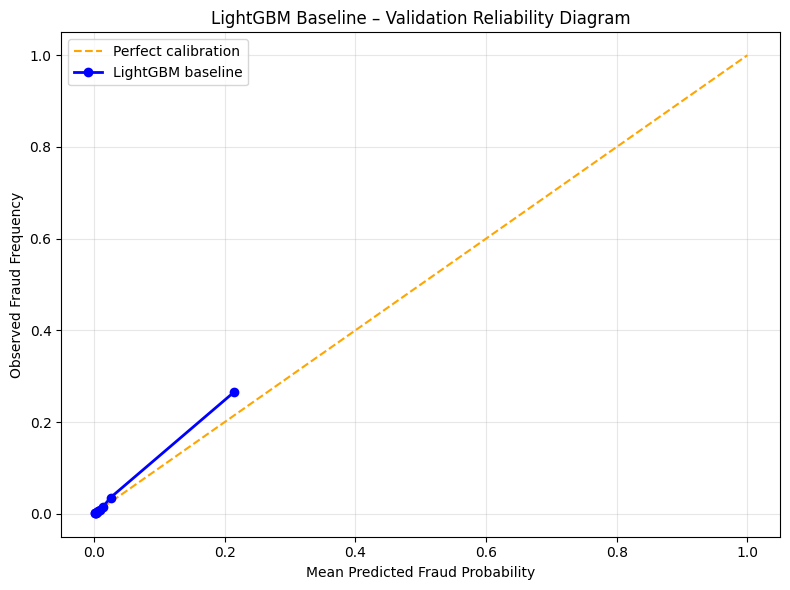

LIGHTGBM BASELINE - CALIBRATION RESULTS
---------------------------------------------
Expected Calibration Error (ECE): 0.0062
Brier Score: 0.0201


In [10]:
# Section 3.9: Probability calibration evaluation

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calculate reliability diagram values
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_val,
    y_val_prob,
    n_bins=10,
    strategy="quantile"
)

# Calculate Expected Calibration Error (ECE)
def calculate_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(
        np.digitize(y_prob, bin_edges[1:-1]),
        0,
        n_bins - 1
    )

    ece = 0.0

    for i in range(n_bins):
        mask = bin_ids == i

        if mask.any():
            actual_fraud_rate = y_true[mask].mean()
            average_prediction = y_prob[mask].mean()
            bin_weight = mask.mean()

            ece += bin_weight * abs(
                actual_fraud_rate - average_prediction
            )

    return ece

ece_score = calculate_ece(y_val, y_val_prob)
brier_score = brier_score_loss(y_val, y_val_prob)

# Plot reliability diagram
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="orange",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    linewidth=2,
    color="blue",
    label="LightGBM baseline"
)

plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.title("LightGBM Baseline – Validation Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("LIGHTGBM BASELINE - CALIBRATION RESULTS")
print("-" * 45)
print("Expected Calibration Error (ECE):", round(ece_score, 4))
print("Brier Score:", round(brier_score, 4))


### 3.10 The Hyperparameter Tuning of LightGBM

This section tunes of the LightGBM baseline model the use of the predefined set of the hyperparameter configurations. The model is trained on the chronological training of the dataset and then compared using the Average Precision (PR -AUC) on dataset validation.

And the configuration with the highest of validation average precision is selected. And the testing dataset remains untouched during the model selection.


In [11]:
 # Section 3.10: LightGBM hyperparameter tuning

import time
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import average_precision_score

# Small tuning search to control Colab computation time
parameter_configs = [
    {"num_leaves": 15, "learning_rate": 0.05, "min_child_samples": 30},
    {"num_leaves": 31, "learning_rate": 0.05, "min_child_samples": 20},
    {"num_leaves": 63, "learning_rate": 0.03, "min_child_samples": 30},
    {"num_leaves": 31, "learning_rate": 0.03, "min_child_samples": 50}
]

tuning_results = []
best_model = None
best_ap = -1

for i, params in enumerate(parameter_configs, start=1):

    print(f"\nTraining configuration {i}/{len(parameter_configs)}")

    model = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=1200,
        num_leaves=params["num_leaves"],
        learning_rate=params["learning_rate"],
        min_child_samples=params["min_child_samples"],
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    start = time.time()

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="average_precision",
        callbacks=[
            lgb.early_stopping(50, first_metric_only=True, verbose=False)
        ]
    )

    elapsed = time.time() - start
    probabilities = model.predict_proba(X_val)[:, 1]
    ap = average_precision_score(y_val, probabilities)

    tuning_results.append({
        "Configuration": i,
        "Num Leaves": params["num_leaves"],
        "Learning Rate": params["learning_rate"],
        "Min Child Samples": params["min_child_samples"],
        "Best Iteration": model.best_iteration_,
        "Validation AP": round(ap, 5),
        "Training Time (s)": round(elapsed, 2)
    })

    print(f"Validation AP: {ap:.5f}")

    if ap > best_ap:
        best_ap = ap
        best_model = model
        best_params = params.copy()

tuning_results_df = pd.DataFrame(tuning_results)

print("\nLIGHTGBM HYPERPARAMETER TUNING RESULTS")
print("-" * 55)

display(tuning_results_df)

print("\nBest configuration:", best_params)
print("Best validation AP:", round(best_ap, 5))



Training configuration 1/4
Validation AP: 0.59065

Training configuration 2/4
Validation AP: 0.61464

Training configuration 3/4
Validation AP: 0.62161

Training configuration 4/4
Validation AP: 0.60687

LIGHTGBM HYPERPARAMETER TUNING RESULTS
-------------------------------------------------------


,Configuration,Num Leaves,Learning Rate,Min Child Samples,Best Iteration,Validation AP,Training Time (s)
0,1,15,0.05,30,1187,0.59065,105.71
1,2,31,0.05,20,1191,0.61464,109.26
2,3,63,0.03,30,1169,0.62161,137.13
3,4,31,0.03,50,1199,0.60687,113.59



Best configuration: {'num_leaves': 63, 'learning_rate': 0.03, 'min_child_samples': 30}
Best validation AP: 0.62161


### The Evaluation of the Tuned LightGBM Model
This section evaluates the best LightGBM model selected during the hyperparameter tuning. And the model it is evaluated on the validation dataset using the average Precision (PR-AUC), ROC – AUC, precision, recall, F1 – score, brier score and a confusion matrix.

These results will help us to understand whether the hyperparameter turning has improved fraud detection while compared with the initial LightGBM baseline. And the testing dataset is reserved for final evaluation.


In [12]:
# Section 3.11: Evaluate the tuned LightGBM model

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

# Predict fraud probabilities using the best tuned model
y_val_prob_tuned = best_model.predict_proba(X_val)[:, 1]

# Convert probabilities into fraud predictions
# 0 = legitimate transaction, 1 = fraudulent transaction
threshold = 0.5
y_val_pred_tuned = (y_val_prob_tuned >= threshold).astype(int)

# Calculate evaluation metrics
tuned_ap = average_precision_score(y_val, y_val_prob_tuned)
tuned_roc_auc = roc_auc_score(y_val, y_val_prob_tuned)
tuned_precision = precision_score(y_val, y_val_pred_tuned, zero_division=0)
tuned_recall = recall_score(y_val, y_val_pred_tuned, zero_division=0)
tuned_f1 = f1_score(y_val, y_val_pred_tuned, zero_division=0)
tuned_brier = brier_score_loss(y_val, y_val_prob_tuned)

# Display results
print("TUNED LIGHTGBM VALIDATION RESULTS")
print("-" * 45)
print(f"Average Precision (PR-AUC): {tuned_ap:.4f}")
print(f"ROC-AUC: {tuned_roc_auc:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall: {tuned_recall:.4f}")
print(f"F1-score: {tuned_f1:.4f}")
print(f"Brier Score: {tuned_brier:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 45)
print(confusion_matrix(y_val, y_val_pred_tuned))


TUNED LIGHTGBM VALIDATION RESULTS
---------------------------------------------
Average Precision (PR-AUC): 0.6216
ROC-AUC: 0.9300
Precision: 0.8803
Recall: 0.3748
F1-score: 0.5257
Brier Score: 0.0197

CONFUSION MATRIX
---------------------------------------------
[[85384   155]
 [ 1902  1140]]


### 3.12 The Comparison of the Initial and the Tunel LightGBM Models

This section compares the initials LightGBM baseline with the tuned LightGBM model using the validation performance. Then the comparison helps to determine whether hyperparameter turning improves the fraud detection before comparing the baseline with the deep learning models.


In [13]:
# Section 3.12: Compare initial and tuned LightGBM models

import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": [
        "Average Precision (PR-AUC)",
        "ROC-AUC",
        "Precision",
        "Recall",
        "F1-score",
        "Brier Score"
    ],
    "Initial LightGBM": [
        0.6093,
        0.9263,
        0.8689,
        0.3616,
        0.5107,
        0.0201
    ],
    "Tuned LightGBM": [
        tuned_ap,
        tuned_roc_auc,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_brier
    ]
})

print("INITIAL VS TUNED LIGHTGBM COMPARISON")
print("-" * 45)

display(comparison_df.round(4))

INITIAL VS TUNED LIGHTGBM COMPARISON
---------------------------------------------


,Metric,Initial LightGBM,Tuned LightGBM
0,Average Precision (PR-AUC),0.6093,0.6216
1,ROC-AUC,0.9263,0.9300
2,Precision,0.8689,0.8803
3,Recall,0.3616,0.3748
4,F1-score,0.5107,0.5257
5,Brier Score,0.0201,0.0197


### 3.13 The Calibration of the Tuned LighGBM Model

This selection evaluates whether the tuned LightBBM model produces the reliable fraud probability estimates. A reliability diagram, Expected Calibration errors (ECE), and the brier score are used to assess the probability calibration on the validation dataset.


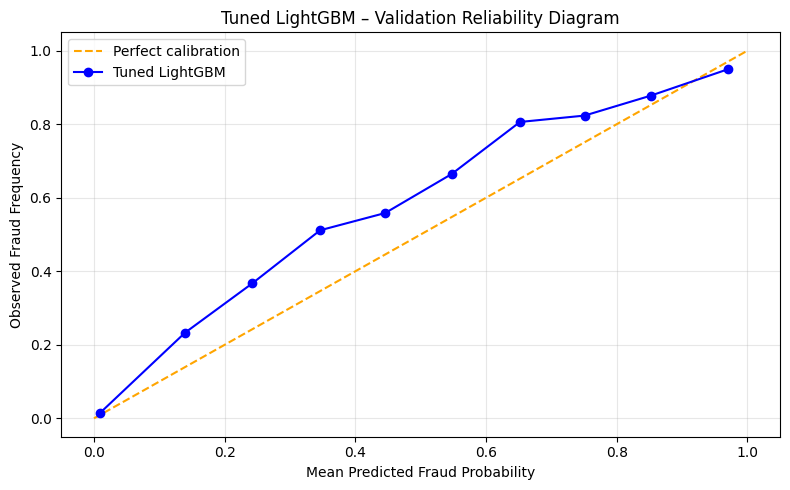

TUNED LIGHTGBM CALIBRATION RESULTS
---------------------------------------------
Expected Calibration Error (ECE): 0.0084
Brier Score: 0.0197


In [14]:
# Section 3.13: Calibration of the tuned LightGBM model

import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calculate reliability diagram values
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_val,
    y_val_prob_tuned,
    n_bins=10,
    strategy="uniform"
)

# Plot reliability diagram
plt.figure(figsize=(8, 5))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="orange",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    color="blue",
    label="Tuned LightGBM"
)

plt.xlabel("Mean Predicted Fraud Probability")
plt.ylabel("Observed Fraud Frequency")
plt.title("Tuned LightGBM – Validation Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate ECE using all validation transactions
def calculate_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(np.digitize(y_prob, bin_edges) - 1, 0, n_bins - 1)

    ece = 0.0

    for i in range(n_bins):
        mask = bin_ids == i

        if np.any(mask):
            observed_rate = np.mean(y_true[mask])
            predicted_rate = np.mean(y_prob[mask])
            weight = np.mean(mask)

            ece += weight * abs(observed_rate - predicted_rate)

    return ece

tuned_ece = calculate_ece(y_val, y_val_prob_tuned)
tuned_brier = brier_score_loss(y_val, y_val_prob_tuned)

print("TUNED LIGHTGBM CALIBRATION RESULTS")
print("-" * 45)
print(f"Expected Calibration Error (ECE): {tuned_ece:.4f}")
print(f"Brier Score: {tuned_brier:.4f}")


### 3.14 Save the LightGBM Baseline Results

This section saves the tuned LightGBM models’ validation performance, selected hyperparameters and the training information. Then, these results will be used to compare the baseline with the deep learning models in later experiments.


In [15]:
# Section 3.14: Save tuned LightGBM validation results

import os
import json
import pandas as pd
import joblib

from google.colab import files

# Create results folder
os.makedirs("results", exist_ok=True)

# Store validation metrics
baseline_results = {
    "model": "Tuned LightGBM",
    "dataset": "IEEE-CIS Fraud Detection",
    "evaluation_split": "validation",
    "random_state": 42,
    "average_precision": float(tuned_ap),
    "roc_auc": float(tuned_roc_auc),
    "precision": float(tuned_precision),
    "recall": float(tuned_recall),
    "f1_score": float(tuned_f1),
    "brier_score": float(tuned_brier),
    "ece": float(tuned_ece),
    "best_parameters": best_params,
    "best_iteration": int(best_model.best_iteration_)
}

# Save metrics as JSON
results_path = "results/lightgbm_baseline_results.json"

with open(results_path, "w") as f:
    json.dump(baseline_results, f, indent=4)

# Save hyperparameter tuning table
tuning_results_df.to_csv(
    "results/lightgbm_tuning_results.csv",
    index=False
)

# Save trained model
joblib.dump(
    best_model,
    "results/lightgbm_tuned_model.joblib"
)

print("LIGHTGBM RESULTS SAVED SUCCESSFULLY")
print("-" * 45)
print("Files created:")
print(os.listdir("results"))

# Download files
files.download(results_path)
files.download("results/lightgbm_tuning_results.csv")
files.download("results/lightgbm_tuned_model.joblib")


LIGHTGBM RESULTS SAVED SUCCESSFULLY
---------------------------------------------
Files created:
['lightgbm_tuned_model.joblib', 'lightgbm_baseline_results.json', 'lightgbm_tuning_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###3.15 The Summary of the LightGBM Baseline Modelling

In this notebook, the LightGBM was trained and evaluated using the IEEE-AUC Fraud Detection dataset. Then, the dataset was divided chronologically into training, validation and testing sets to reduce the risk of data leakage. Hyperparameter tuning improved the validation PR-AUC from 0,6093 to 0, 6216. The tant model achieved the precision of 0, 8803 and the recall of the zero, 3748 at the classification threshold of 0, 5. And this results it shows that the model identifies fraud with the relatively high precision but still misses some of the fraudulent transactions.

The turned lightGBM model will then be used as the baseline for the comparison with the deep learning models and the final testing data set will be reserved for the evaluation after the model development and selection.
